# plot styling

yabplot provides several styling presets and customization options to make your figures publication-ready.

in this tutorial, we will explore:
1. lighting styles.
2. customizing the background context brain.
3. handling missing data (`nan_color`, `nan_alpha`).
4. tract-specific visualizations.
5. region boundary contours (`contours`).

In [30]:
import yabplot as yab
import matplotlib.pyplot as plt
import numpy as np

## 1. lighting styles
different styles can highlight shape (sculpted) or data values (flat/matte). available styles include: `'default'`, `'matte'`, `'glossy'`, `'sculpted'`, `'flat'`.

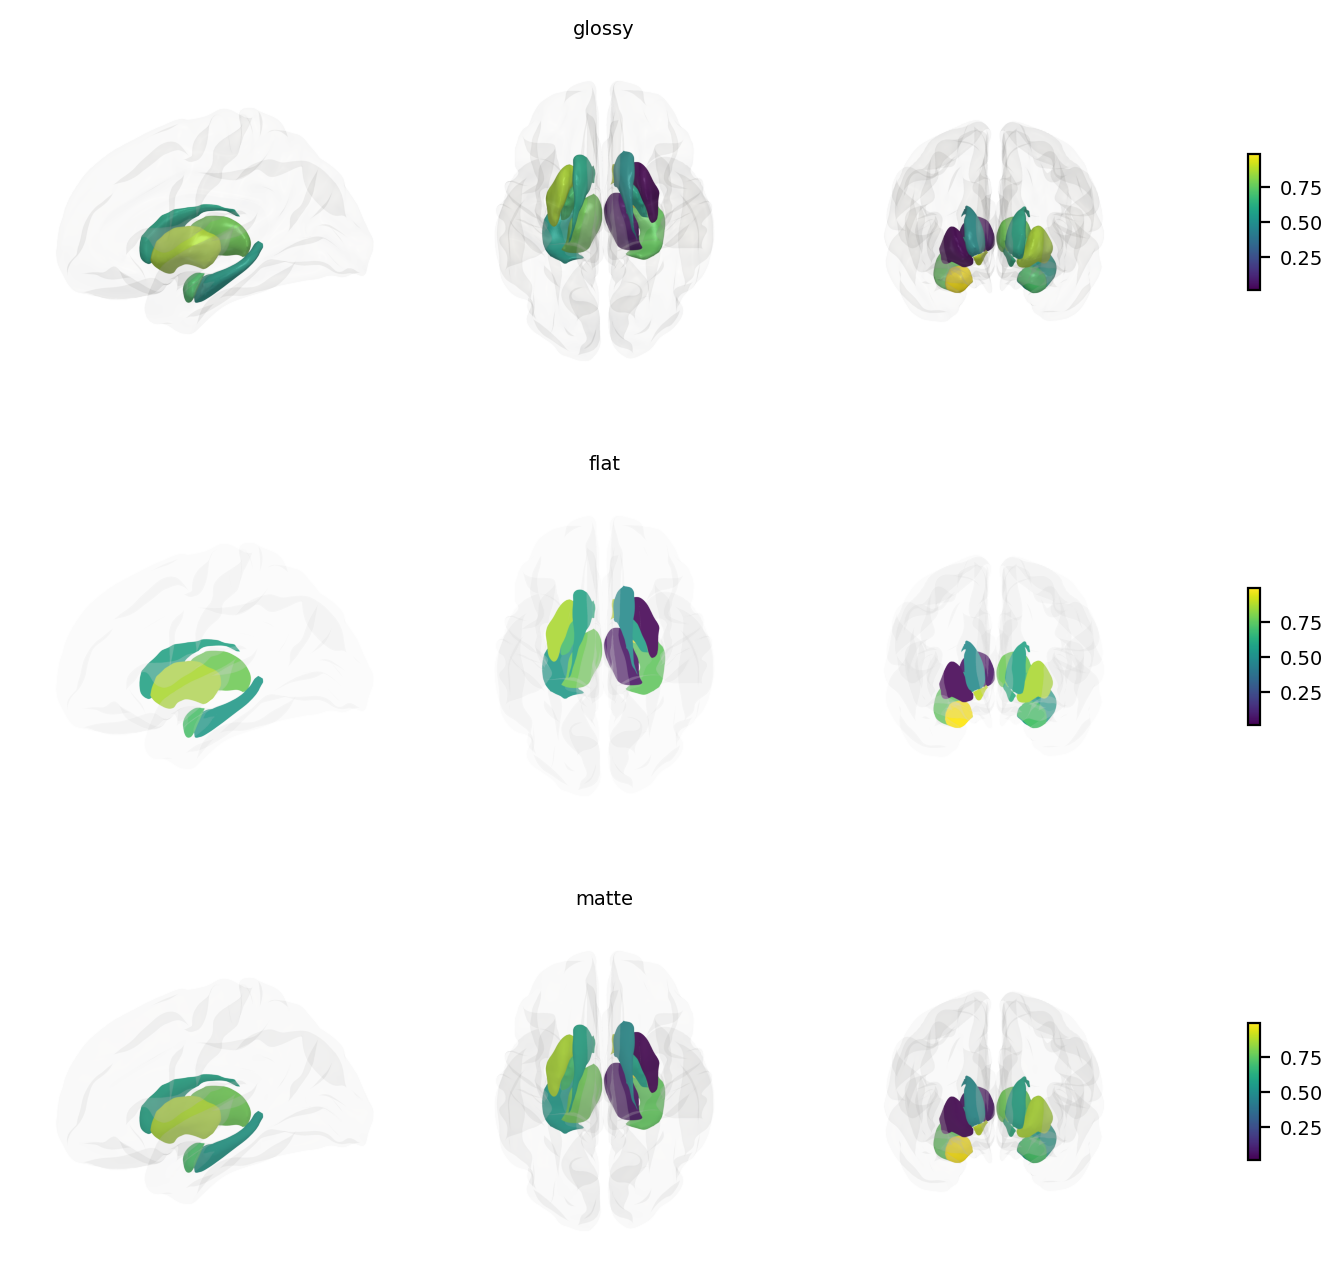

In [31]:
# generate random data for demonstration
regions = yab.get_atlas_regions('aseg', 'subcortical')
data = np.random.rand(len(regions))

fig, axes = plt.subplots(3, 1, figsize=(8, 8), dpi=200)

# compare 'flat' vs 'glossy' vs 'matte' styles
# - glossy enhances the 3d curvature giving it a shiny look
# - flat is great for seeing exact data colors without shadows
# - matte is a balance between both
for i, style in enumerate(['glossy', 'flat', 'matte']):
    axes[i] = yab.plot_subcortical(
        data=data,
        ax = axes[i],
        cmap='viridis',
        atlas='aseg',
        views=['left_lateral', 'superior', 'anterior'],
        style=style
    )
    axes[i].set_title(style, fontsize=7)

## 2. context brain (bmesh)
for subcortical and tract plots, a context brain mesh is rendered to show anatomical location. you can change its style or hide it.

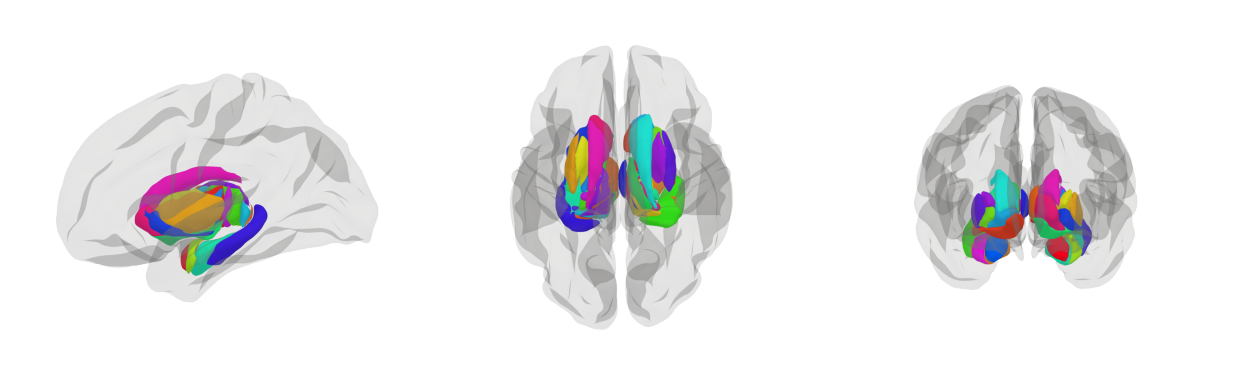

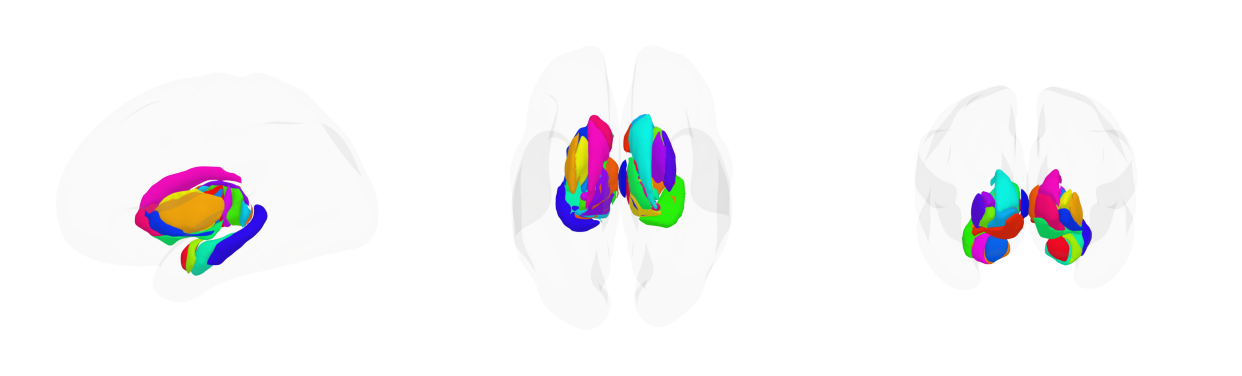

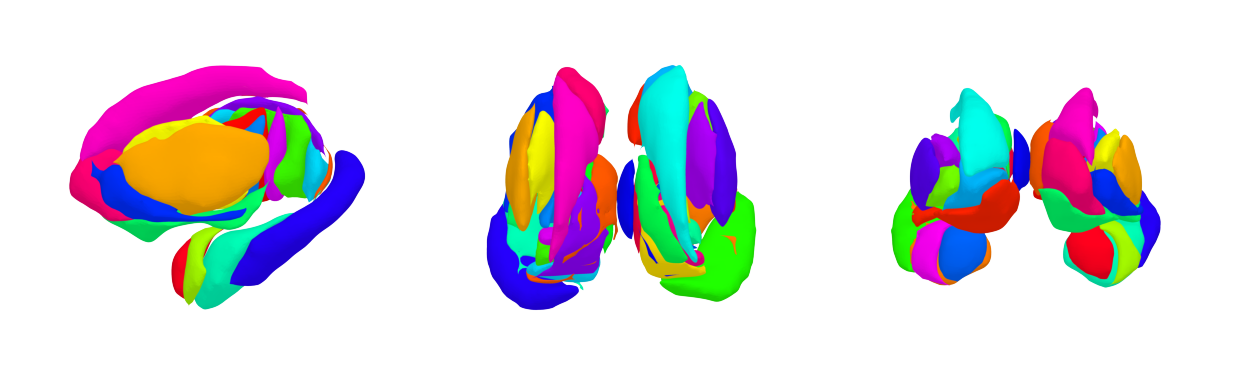

In [32]:
# styling the context brain
ax = yab.plot_subcortical(
    atlas='brainnetome_sc',
    views=['left_lateral', 'superior', 'anterior'],
    bmesh='midthickness',       # standard surface
    bmesh_alpha=0.25,            # less transparent
    bmesh_color='gray',         # dark background mesh
)
ax = yab.plot_subcortical(
    atlas='brainnetome_sc',
    views=['left_lateral', 'superior', 'anterior'],
    bmesh='inflated',         # inflated surface
    bmesh_alpha=0.1,         # very transparent
    bmesh_color='gray',       # dark background mesh
)

# hiding the context brain
ax = yab.plot_subcortical(
    atlas='brainnetome_sc',
    views=['left_lateral', 'superior', 'anterior'],
    bmesh=None,               # no context surface
)

## 3. handling missing data (nan)
when plotting dictionaries or incomplete arrays, you can control how missing regions appear using `nan_color` and `nan_alpha`.

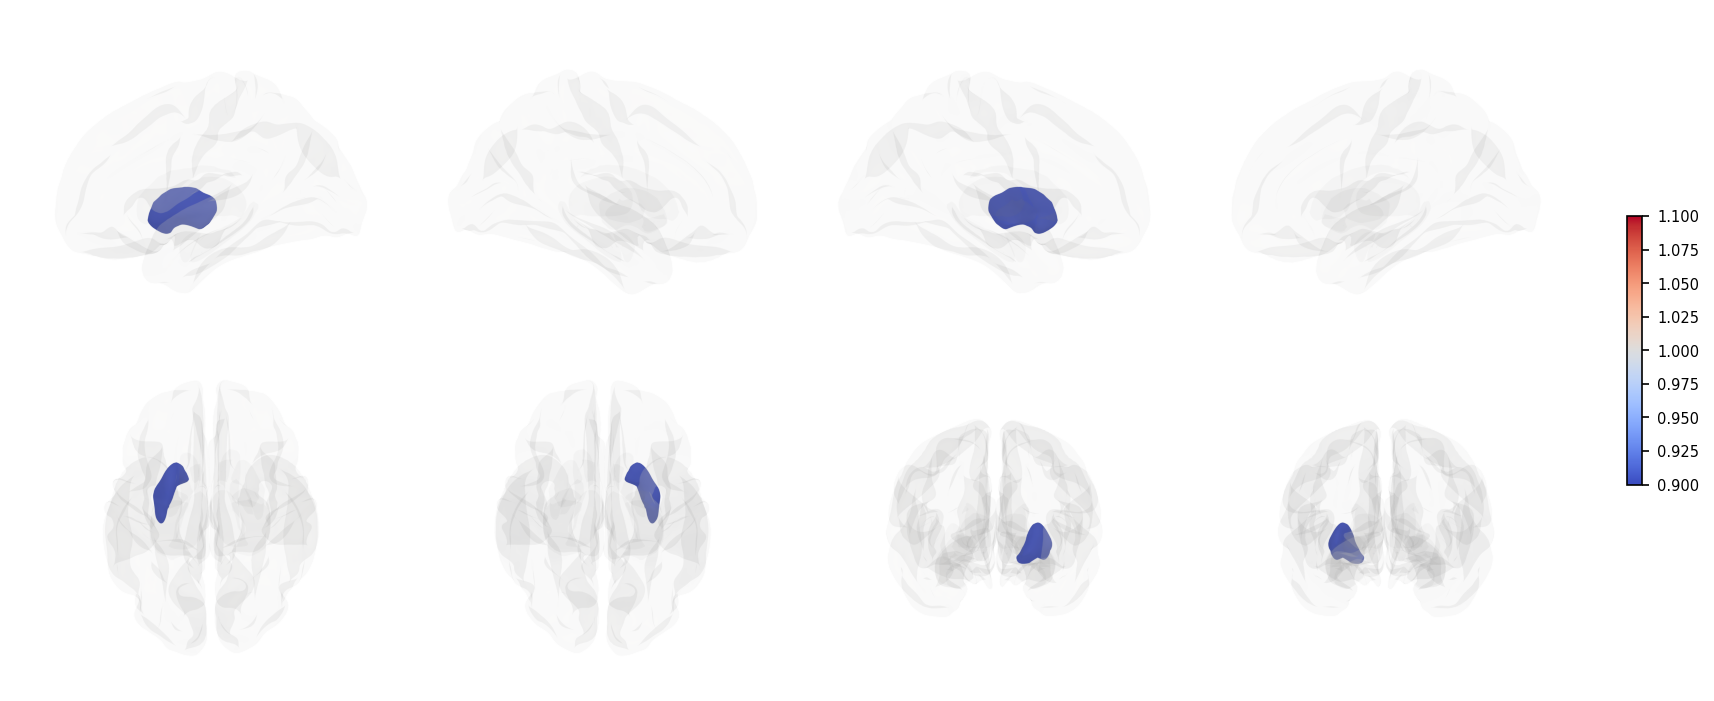

In [33]:
# define data for only one region
sparse_data = {'Left-Putamen': 1.0}

ax = yab.plot_subcortical(
    data=sparse_data,
    atlas='aseg',
    # make missing regions white and almost transparent
    nan_color='gray',
    nan_alpha=0.05,
    style='matte'
)

## 4. tract customization
for white matter tracts, you can pass specific parameters to pyvista to change the rendering of lines/tubes via `tract_kwargs`.

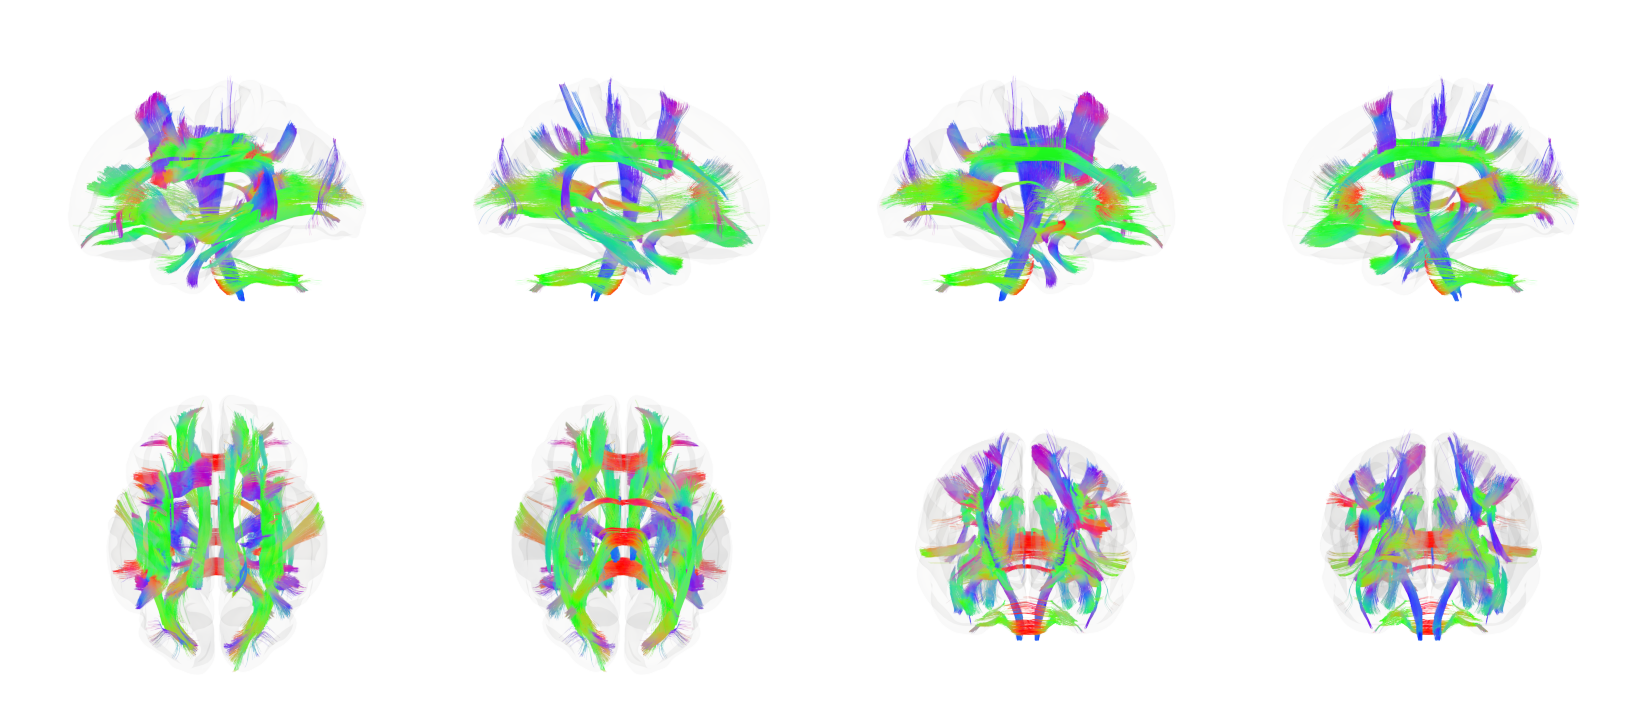

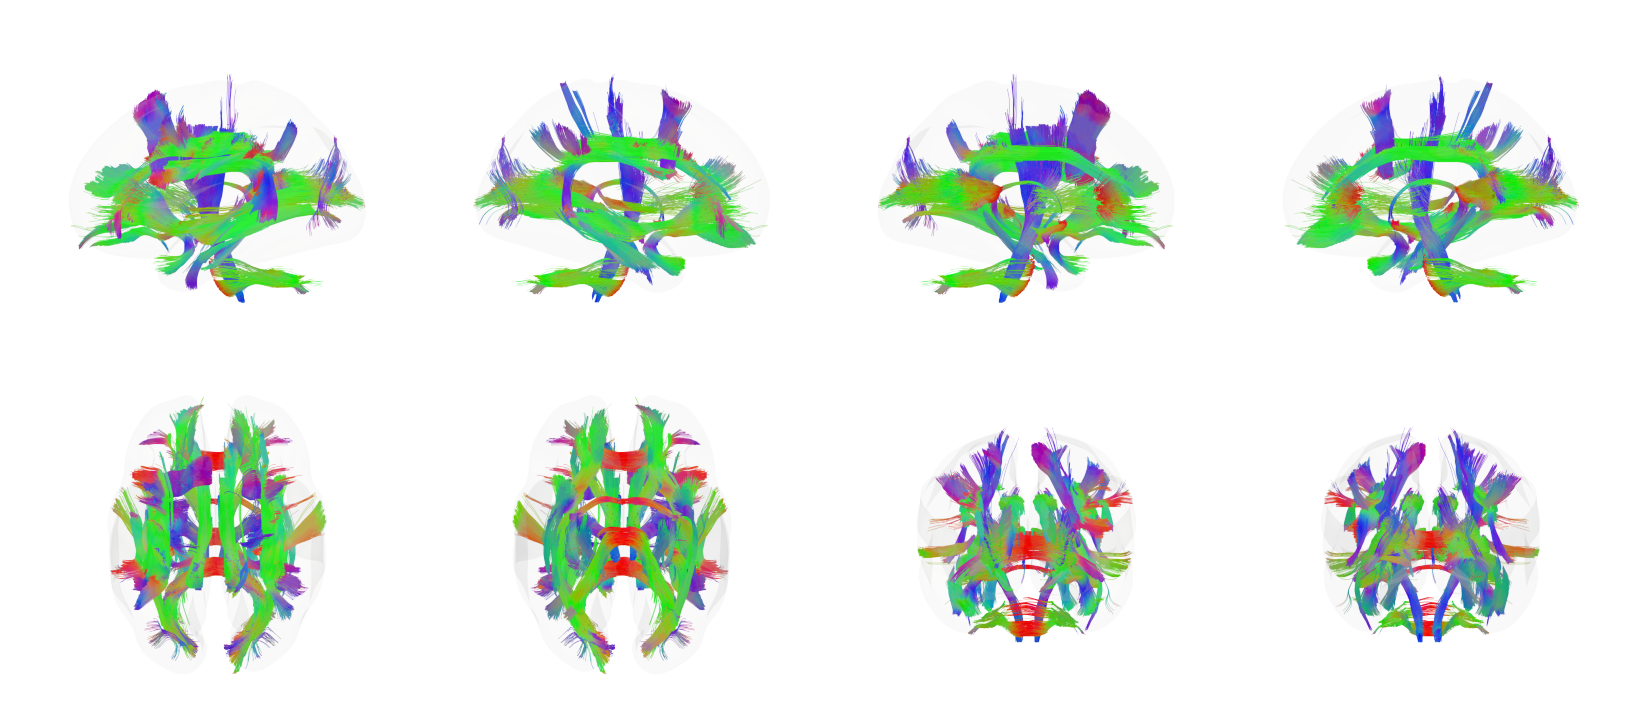

In [36]:
# render tracts as thin lines instead of 3d tubes (faster, different look)
ax = yab.plot_tracts(
    atlas='xtract_medium',
    orientation_coloring=True,
    bmesh='pial',
    tract_kwargs={
        'render_lines_as_tubes': False,  # simple lines
        'line_width': 2.0                # slightly thicker lines
    },
)

# render as thick tubes
ax = yab.plot_tracts(
    atlas='xtract_medium',
    orientation_coloring=True,
    bmesh='inflated',
    tract_kwargs={
        'render_lines_as_tubes': True,
        'line_width': 4.0  # very thick tubes
    },
)

## 5. region boundary contours
for cortical plots, `contours` draws the borders between atlas regions: `True` for all regions, a list of region names or a boolean mask for some of them, or a dict to change the style (`color`, `line_width` in mm, `opacity`).

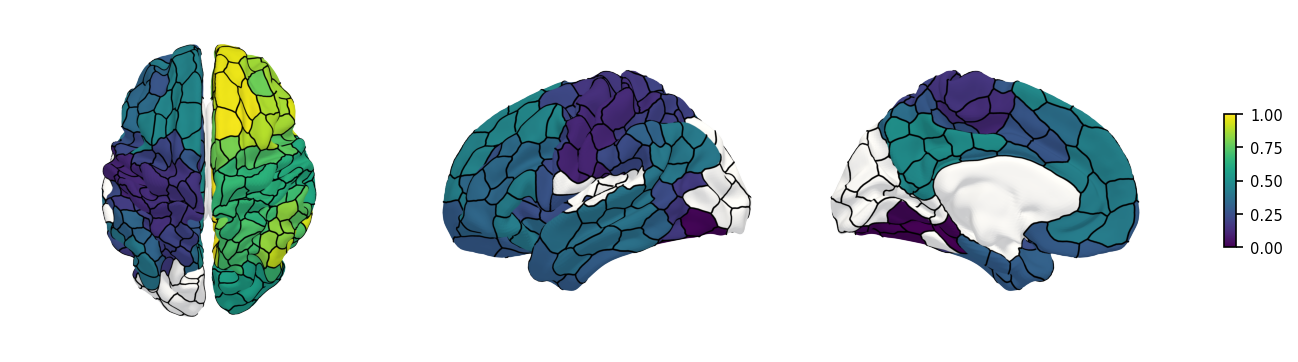

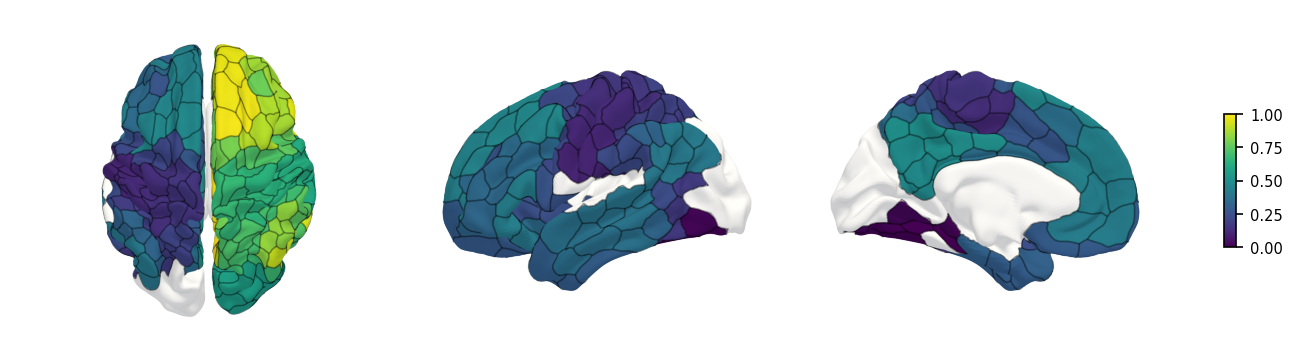

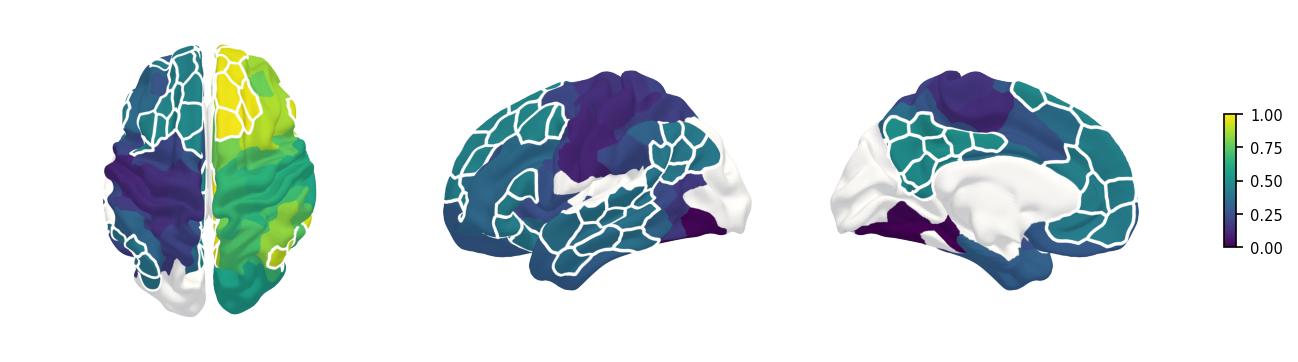

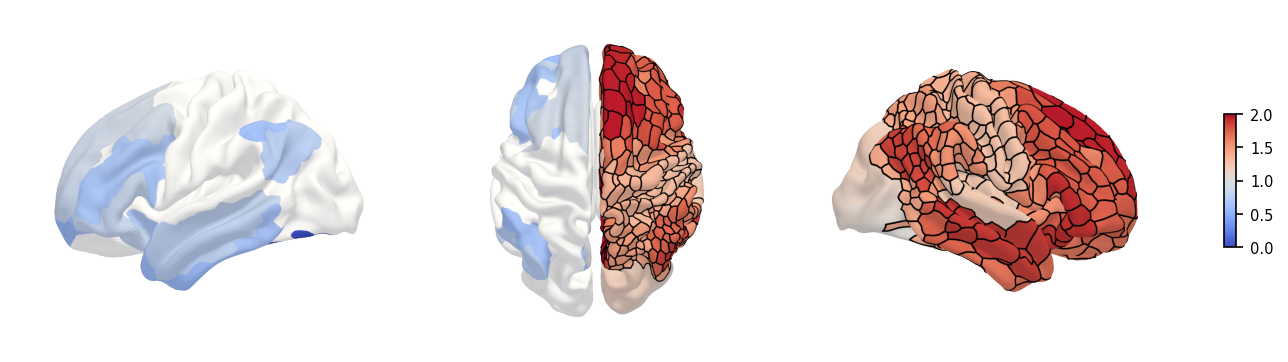

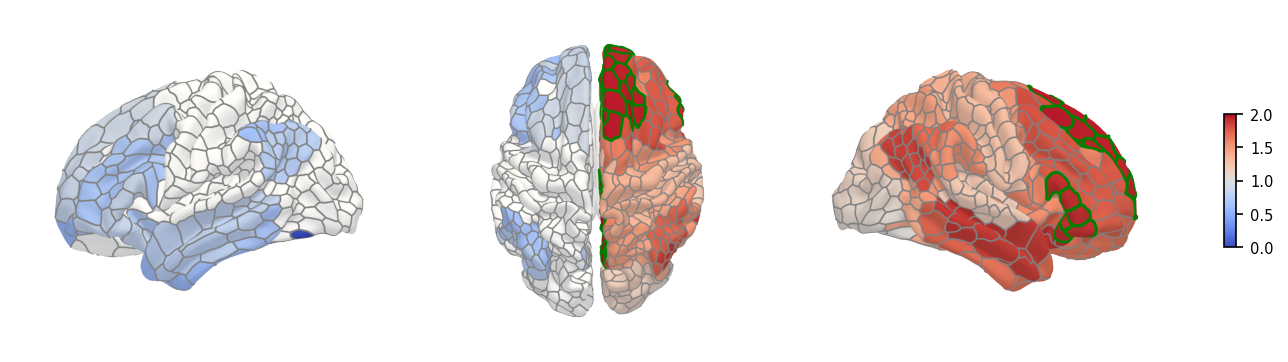

In [39]:
# example data with some missing regions
regions = yab.get_atlas_regions('schaefer400', 'cortical')
data = np.linspace(0, 1, len(regions))
data[10:40] = np.nan

regions2 = yab.get_atlas_regions('schaefer1000', 'cortical')
data2 = np.linspace(0, 2, len(regions2))
data2[10:300] = np.nan

# outline all regions
ax = yab.plot_cortical(
    data=data, atlas='schaefer400', cmap='viridis',
    views=['superior', 'left_lateral', 'left_medial'],
    contours=True,
)

# outline only the regions that have data and change opacity
ax = yab.plot_cortical(
    data=data, atlas='schaefer400', cmap='viridis',
    views=['superior', 'left_lateral', 'left_medial'],
    contours={'color': 'black', 'line_width': 1.0, 'opacity': 0.4, 'include_nan': False}
)

# give specific regions their own style
ax = yab.plot_cortical(
    data=data, atlas='schaefer400', cmap='viridis',
    views=['superior', 'left_lateral', 'left_medial'],
    contours={name: {'color': 'white', 'line_width': 2.0} for name in regions if 'Default' in name},
)

# pick the regions from their values, e.g. outline the strongest effects
ax = yab.plot_cortical(
    data=data2, atlas='schaefer1000',
    views=['left_lateral', 'superior', 'right_lateral'],
    contours=np.abs(data2) > 1.2,
)

# thin borders everywhere and thick ones around the regions of interest
thin, thick = {'color': 'gray', 'line_width': 1.0}, {'color': 'green', 'line_width': 2.0}
ax = yab.plot_cortical(
    data=data2, atlas='schaefer1000',
    views=['left_lateral', 'superior', 'right_lateral'],
    contours={name: thick if value > 1.9 else thin for name, value in zip(regions2, data2)},
)